# 08. M2 con los corpus peruano y boliviano

Se continúa desde M1, que ya fue ajustado con SMPS. En esta etapa se realizan tres épocas con la partición boliviana de entrenamiento, usando `texto_procesado` y `etiqueta_humana`. Se usa la partición boliviana de ajuste guardada.

La corrida se elige en `corrida.json`. Las evaluaciones reproducidas se guardan en `salidas/<ejecución>/evaluacion`.

Si abres este cuaderno directamente en Colab, ejecuta su primera celda y autoriza Google Drive cuando se solicite. Para recorrer toda la secuencia de una vez, usa `INICIAR_EN_COLAB.ipynb`.

**Modo de revisión docente.** Puedes ejecutar todas las celdas con las opciones predeterminadas. Se verifican los pesos y se leen las predicciones de evaluación guardadas para reconstruir las tablas y gráficas. Los nuevos ajustes requieren activar `ENTRENAR_MODELO`; las nuevas predicciones de evaluación requieren `RECALCULAR_EVALUACION`. `PREGUNTAR_CARGA` permite habilitar las preguntas manuales.

Las salidas visibles al abrir el cuaderno proceden de `corrida_03_epocas`. Los registros de M1 y M2 corresponden a sus ajustes originales de tres épocas. Una nueva ejecución en modo de revisión muestra los registros y las métricas guardadas. Nunca se presenta la lectura de un historial como un nuevo entrenamiento.

In [1]:
# Inicio al abrir este cuaderno directamente en Google Colab.
from pathlib import Path

if not Path("corrida.json").is_file():
    import os
    import subprocess
    import sys

    try:
        from google.colab import drive
    except ImportError as error:
        raise FileNotFoundError("En Jupyter, abre la carpeta que contiene corrida.json.") from error

    proyecto_drive = Path("/content/drive/MyDrive/Tesis_RoBERTuito_M0_M1_M2")
    if not (proyecto_drive / "corrida.json").is_file():
        drive.mount("/content/drive", timeout_ms=180000)
    if not (proyecto_drive / "corrida.json").is_file():
        raise FileNotFoundError("Busca Tesis_RoBERTuito_M0_M1_M2 directamente en Mi unidad.")

    os.chdir(proyecto_drive)
    sys.path.insert(0, str(proyecto_drive))
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r",
         str(proyecto_drive / "requirements-cuadernos.txt")],
        check=True,
    )
    print("Carpeta de la tesis conectada:", proyecto_drive)

import json
from pathlib import Path

RAIZ = Path.cwd()
CORRIDA = json.loads((RAIZ / "corrida.json").read_text(encoding="utf-8"))["corrida"]
EPOCAS = 3
SALIDAS = RAIZ / 'modelos' / CORRIDA

# Primera revisión del modelo y confirmación antes de leer el corpus.
import os
from gestion_modelos import preguntar_modelo, nueva_corrida

MODELO = "M2"
ENTRENAR_MODELO = False  # @param {type:"boolean"}
PREGUNTAR_CARGA = False  # @param {type:"boolean"}
RECALCULAR_EVALUACION = False  # @param {type:"boolean"}

ENTRENAR_MODELO = ENTRENAR_MODELO or os.environ.get("TESIS_PERMITIR_ENTRENAMIENTO") == "1"
RECALCULAR_EVALUACION = RECALCULAR_EVALUACION or ENTRENAR_MODELO
respuesta = os.environ.get("TESIS_RESPUESTA_M2")
if respuesta is None:
    respuesta = "no" if ENTRENAR_MODELO else (None if PREGUNTAR_CARGA else "si")
CARGAR_GUARDADO = preguntar_modelo(
    RAIZ, MODELO, respuesta=respuesta, permitir_preparacion=ENTRENAR_MODELO
)

In [2]:
# La lectura del corpus se realiza cuando se solicita un ajuste nuevo.

## Código del entrenamiento

Este bloque de `entrenamiento.ajustar` configura las tres épocas y llama a `entrenador.train()`. El cuaderno ejecuta esa función cuando eliges preparar un modelo nuevo.

```python
    modelo, tokenizer = cargar_modelo(origen)
    dataset, recuentos = codificar(datos, tokenizer)
    print(f"{nombre} | {len(dataset)} registros | {torch.cuda.get_device_name()} | {epocas} épocas")
    with TemporaryDirectory() as temporal:
        argumentos = TrainingArguments(
            output_dir=temporal,
            seed=SEMILLA,
            data_seed=SEMILLA,
            num_train_epochs=epocas,
            per_device_train_batch_size=16,
            learning_rate=2e-5,
            group_by_length=True,
            bf16=torch.cuda.is_bf16_supported(),
            eval_strategy="no",
            save_strategy="no",
            logging_steps=50,
            disable_tqdm=True,
            report_to=[],
        )
        entrenador = Trainer(
            model=modelo,
            args=argumentos,
            train_dataset=dataset,
            data_collator=DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8),
            processing_class=tokenizer,
        )
        resultado = entrenador.train()
```

### Registro del entrenamiento ya realizado

La salida guardada muestra el ajuste original de tres épocas. Al ejecutar esta sección en modo de revisión se cargan los pesos y se muestra el historial de pérdida guardado.

In [3]:
destino = SALIDAS / MODELO
if CARGAR_GUARDADO:
    print("Se utilizarán los pesos guardados de M2.")
    import pandas as pd
    from IPython.display import display
    print("Historial de pérdida del entrenamiento guardado:")
    display(pd.read_csv(destino / "perdida_entrenamiento.csv"))
else:
    if not ENTRENAR_MODELO:
        raise RuntimeError("Activa ENTRENAR_MODELO para solicitar un ajuste nuevo. La revisión utiliza los pesos incluidos.")
    import torch
    from entrenamiento import leer_bolivia, ajustar

    if not torch.cuda.is_available():
        raise RuntimeError("Para entrenar M2, usa un entorno con GPU CUDA. Para usar los pesos incluidos, vuelve a ejecutar la primera celda y responde sí.")
    if destino.exists():
        CORRIDA = nueva_corrida(RAIZ, MODELO)
        SALIDAS = RAIZ / "modelos" / CORRIDA
        destino = SALIDAS / MODELO
    from rutas import carpeta_salidas
    validada = carpeta_salidas(RAIZ) / "TABLAS/05_clasificacion/clasificacion_asistida_v5_etiquetada.xlsx"
    datos, procedencia = leer_bolivia(RAIZ, anotacion=validada if validada.is_file() else None)
    ajustar(MODELO, SALIDAS / "M1", destino, datos, procedencia, epocas=EPOCAS, permitir=ENTRENAR_MODELO)

M2 | 1809 registros | NVIDIA GeForce RTX 4060 | 3 épocas


{'loss': 0.5543, 'grad_norm': 10.995086669921875, 'learning_rate': 1.7076023391812867e-05, 'epoch': 0.43859649122807015}


{'loss': 0.4152, 'grad_norm': 6.834593296051025, 'learning_rate': 1.4152046783625733e-05, 'epoch': 0.8771929824561403}


{'loss': 0.352, 'grad_norm': 6.747904300689697, 'learning_rate': 1.1228070175438597e-05, 'epoch': 1.3157894736842106}


{'loss': 0.2453, 'grad_norm': 7.176421165466309, 'learning_rate': 8.304093567251463e-06, 'epoch': 1.7543859649122808}


{'loss': 0.2268, 'grad_norm': 11.440765380859375, 'learning_rate': 5.380116959064328e-06, 'epoch': 2.192982456140351}


{'loss': 0.1774, 'grad_norm': 31.2122802734375, 'learning_rate': 2.456140350877193e-06, 'epoch': 2.6315789473684212}


{'train_runtime': 28.6982, 'train_samples_per_second': 189.106, 'train_steps_per_second': 11.917, 'train_loss': 0.30236177416572796, 'epoch': 3.0}


Guardado: modelos\corrida_03_epocas\M2


## Seguimiento del ajuste de M2

El ajuste con el corpus boliviano usa **entropía cruzada multiclase**. Para una publicación,
la pérdida es el negativo del logaritmo de la probabilidad que el modelo asigna
a su etiqueta de referencia. PyTorch calcula esta pérdida al recibir los textos
tokenizados y sus etiquetas en `ajustar`. El entrenador registra un promedio cada
50 pasos de optimización.

La figura muestra esos promedios a lo largo de las tres épocas. Las líneas
verticales marcan el final de la primera y segunda época. El gráfico corresponde
al entrenamiento. La evaluación sobre las 454 publicaciones aparece en la
sección siguiente.

Para ver la curva de los pesos guardados, puedes ejecutar esta celda directamente.
Usa `CORRIDA_SEGUIMIENTO` para indicar qué ejecución se quiere mostrar.

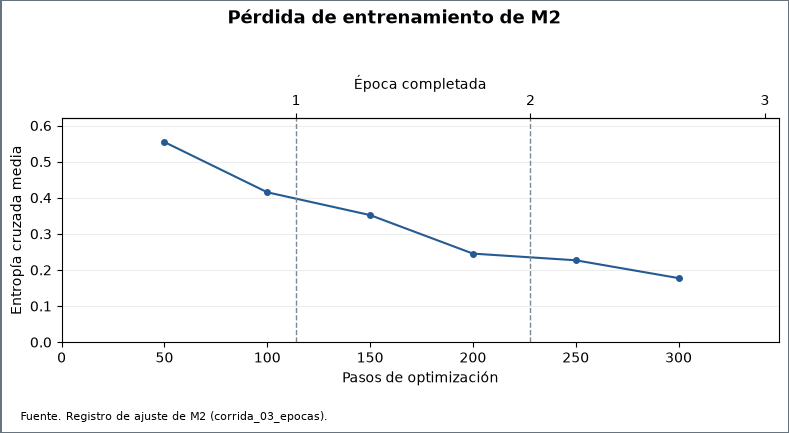

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

CORRIDA_SEGUIMIENTO = json.loads(Path("corrida.json").read_text(encoding="utf-8"))["corrida"]
modelo = "M2"
carpeta = Path("modelos") / CORRIDA_SEGUIMIENTO / modelo
datos = pd.read_csv(carpeta / "perdida_entrenamiento.csv")
ejecucion = json.loads((carpeta / "ejecucion.json").read_text(encoding="utf-8"))
pasos_totales = ejecucion["pasos_optimizacion"]
epocas = int(ejecucion["epocas"])
pasos_epoca = pasos_totales // epocas

fig, ax = plt.subplots(figsize=(8.5, 4.3))
fig.patch.set_edgecolor("#667480")
fig.patch.set_linewidth(1)
fig.suptitle(f"Pérdida de entrenamiento de {modelo}", fontsize=13, fontweight="bold")
ax.plot(datos["paso"], datos["perdida"], "o-", color="#245b93", markersize=4)
for epoca in range(1, epocas):
    ax.axvline(epoca * pasos_epoca, color="#7b8794", linestyle="--", linewidth=1)
ax.set(xlabel="Pasos de optimización", ylabel="Entropía cruzada media",
       xlim=(0, pasos_totales * 1.02), ylim=(0, datos["perdida"].max() * 1.12))
ax.grid(axis="y", alpha=0.22)
superior = ax.secondary_xaxis("top")
superior.set_xticks([n * pasos_epoca for n in range(1, epocas + 1)],
                   [str(n) for n in range(1, epocas + 1)])
superior.set_xlabel("Época completada")
fig.text(0.06, 0.025, f"Fuente. Registro de ajuste de {modelo} ({CORRIDA_SEGUIMIENTO}).", fontsize=8)
fig.tight_layout(rect=(0.03, 0.07, 0.97, 0.94))
plt.show()

## Evaluación de M2

Esta sección se puede ejecutar desde aquí con los pesos guardados. Usa las **454 publicaciones**
de la partición boliviana marcadas como `validacion` en el archivo del split de 1.809/454.
Para la corrida experimental sirven como conjunto de evaluación.

Cada publicación aporta un voto. Se usa su `texto_procesado`, se aplica
`preprocess_tweet(lang='es')` y se tokeniza en tramos de hasta 128 tokens con 32 de
solapamiento. Se promedian las probabilidades de los tramos y se toma la clase de mayor
probabilidad. La referencia es `etiqueta_humana`.

In [4]:
from rutas import carpeta_salidas

import json
from pathlib import Path

import pandas as pd

from evaluar import evaluar_modelo, mostrar_cuadro, resumir

CORRIDA_EVALUADA = json.loads(Path("corrida.json").read_text(encoding="utf-8"))["corrida"]
predicciones = evaluar_modelo(Path.cwd(), CORRIDA_EVALUADA, "M2",
    recalcular=RECALCULAR_EVALUACION,
    directorio_evaluacion=carpeta_salidas(Path.cwd()) / "evaluacion",
)

La matriz de confusión (véase Cuadro 1) cuenta publicaciones por etiqueta humana (fila)
y predicción (columna). La diagonal muestra los aciertos. El Cuadro 2 muestra la
exactitud (*accuracy*), que divide los aciertos entre las 454 publicaciones, y el F1
macro, que promedia el F1 de las tres clases con el mismo peso para cada una.

In [5]:
metricas, matriz = resumir(predicciones)
mostrar_cuadro("Cuadro 1. Matriz de confusión de M2", matriz)
mostrar_cuadro("Cuadro 2. Exactitud y F1 macro de M2", pd.DataFrame([metricas], index=["M2"]))
print(f"Aciertos: {matriz.to_numpy().trace()} de {len(predicciones)}")

Predicción,negativa,neutral,positiva
Etiqueta humana,,,
negativa,312,9,5
neutral,19,70,5
positiva,11,4,19


,Exactitud,F1 macro
M2,88.33%,77.61%


Aciertos: 401 de 454
